# CIFAR-10 FCN

## 1. Business Understanding

Tarkoitus on oppia käyttämään ja arvioimaan neuroverkko tekniikoita CIFAR-10 datasetin avulla. Tässä työkirjassa käytämmen FCN (Fully Connected Network) mallia.

## 2. Data Understanding

In [1]:
import os
os.environ["KERAS_BACKEND"] = "tensorflow"

In [2]:
import keras
from keras import layers
print(keras.__version__, keras.backend.backend())
import matplotlib.pyplot as plt
import numpy as np
from tensorflow.keras.utils import to_categorical
import pandas as pd
import time

#AI ehdottama muutos jotta koulutus kayttaisi amd gputa

import tensorflow as tf
tf.config.set_visible_devices([], "GPU")

I0000 00:00:1793191061.995399   14612 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1793191062.046546   14612 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793191063.418180   14612 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


3.15.1 tensorflow


E0000 00:00:1793191064.082807   14612 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


In [3]:
(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()

In [4]:
print(f'x_train shape: {x_train.shape}')
print(f'x_test shape:  {x_test.shape}')
print(f'y_train shape: {y_train.shape}')
print(f'y_test shape:  {y_test.shape}')

x_train shape: (50000, 32, 32, 3)
x_test shape:  (10000, 32, 32, 3)
y_train shape: (50000, 1)
y_test shape:  (10000, 1)


Data pitää sisällään 60,000 32x32 värikuvaa. Se on jaettu koulutus ja testi joukkoihin. Koulutusjoukossa on 50,000 ja testijoukossa 10,000 kuvaa. Kuvilla on 10 eri luokkaa. `airplane`, `automobile`, `bird`, `cat`, `deer`, `dog`, `frog`, `horse`, `ship` ja `truck`. Luokilla ei ole päällekkäisyyksiä, esim `automobile` ja `truck` luokissa ei ole samantyyppisiä autoja.
[lähde](https://cave.cs.toronto.edu/kriz/cifar.html)

## 3. Data Preprocessing

In [15]:
(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()

x_train = x_train.astype("float32") / 255
x_test = x_test.astype("float32") / 255

mean = x_train.mean(axis=(0, 1, 2))
std = x_train.std(axis=(0, 1, 2))
print("mean:", mean)
print("std: ", std)

x_train = (x_train - mean) / std
x_test = (x_test - mean) / std

X_train = x_train.reshape(50000, 3072)
X_test = x_test.reshape(10000, 3072)

y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)

# --- Data augmentation: horizontal flips (new variables only) --- tekoäly antoi tämän koodin

# Flip training images horizontally
x_train_flipped = np.flip(x_train, axis=2).copy()

# Flatten flipped images
X_train_flipped = x_train_flipped.reshape(50000, 3072)

# Reuse the same one-hot labels
y_train_flipped = y_train.copy()

# Combined dataset: original + flipped images
X_train_augmented = np.concatenate(
    [X_train, X_train_flipped], axis=0
)
y_train_augmented = np.concatenate(
    [y_train, y_train_flipped], axis=0
)

mean: [0.4914009  0.48215896 0.4465308 ]
std:  [0.24703279 0.24348423 0.26158753]


## 4. Modeling

### Neuronien ja kerrosten määrien vertailu

Vertaillaan mallin suorityskykyä neuronien ja kerrosten määrän perusteella.
Kokeilussa on `512`, `256` ja `128` neuronin ensimmäinen kerros, toiseen kerroksen kokeiluilla neuronien määrä puolitetaan.

In [6]:
results = []
histories = {}
def build_model(units, n_layers):
    layers = [keras.Input(shape=(3072,))]
    width = units
    for _ in range(n_layers):
        layers.append(keras.layers.Dense(width, activation="relu"))
        width = max(width // 2, 16)
    layers.append(keras.layers.Dense(10, activation="softmax"))
    model = keras.Sequential(layers)
    model.compile(optimizer="adam",
                  loss="categorical_crossentropy",
                  metrics=["accuracy"])
    return model

for units in [128, 256, 512]:
    for n_layers in [1, 2]:
        callbacks = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=3,restore_best_weights=True)]
        keras.utils.set_random_seed(42)
        model = build_model(units, n_layers)

        t0 = time.perf_counter()
        history = model.fit(X_train, y_train, epochs=20, batch_size=64,
                            validation_split=0.2, verbose=0, callbacks=callbacks)
        train_time = time.perf_counter() - t0

        test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
        key = f"{units} neuronia, {n_layers} kerrosta"
        histories[key] = history.history
        best_epoch = int(np.argmin(history.history["val_loss"]))

        results.append({
            "neuronit": units,
            "kerrokset": n_layers,
            "parametreja": model.count_params(),
            "aika_s": train_time / len(history.history["loss"]),
            "paras_epookki": best_epoch + 1,
            "epookkeja_ajettu": len(history.history["loss"]),
            "train_acc": history.history["accuracy"][best_epoch],
            "val_acc": history.history["val_accuracy"][best_epoch],
            "ero_train_val": history.history["accuracy"][best_epoch]
                     - history.history["val_accuracy"][best_epoch],
            "test_acc": test_acc,
        })
        print(key, "->", round(test_acc, 4), f"({train_time/len(history.history['loss']):.1f} s)")
df = pd.DataFrame(results)

128 neuronia, 1 kerrosta -> 0.4737 (1.8 s)
128 neuronia, 2 kerrosta -> 0.4723 (1.8 s)
256 neuronia, 1 kerrosta -> 0.4486 (3.0 s)
256 neuronia, 2 kerrosta -> 0.4776 (3.0 s)
512 neuronia, 1 kerrosta -> 0.4605 (5.6 s)
512 neuronia, 2 kerrosta -> 0.4807 (5.9 s)


In [7]:
df

,neuronit,kerrokset,parametreja,aika_s,paras_epookki,epookkeja_ajettu,train_acc,val_acc,ero_train_val,test_acc
0,128,1,394634,1.809519,4,7,0.538875,0.4756,0.063275,0.4737
1,128,2,402250,1.847786,4,7,0.522525,0.4682,0.054325,0.4723
2,256,1,789258,3.010077,2,5,0.481550,0.4553,0.026250,0.4486
3,256,2,820874,3.042173,4,7,0.531900,0.4686,0.063300,0.4776
4,512,1,1578506,5.612698,2,5,0.485600,0.4608,0.024800,0.4605
5,512,2,1707274,5.944109,4,7,0.533900,0.4760,0.057900,0.4807


Testeistä selviää että mallin koko ei juurikaan paranna mallin suorituskykyä, mutta suuremmalla mallilla jossa `512` neuronia ja `2` kerrosta aika on yli kaksinkertainen per epoch. `val_acc` on paras `256` neuronilla jossa 2 kerrosta, toisessa kerroksessa `128` neuronia.

In [8]:
model = keras.Sequential([
    keras.Input(shape=(3072,)),
    keras.layers.Dense(256, activation="relu"),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dense(10, activation="softmax"),
])
model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)
full_history = model.fit(X_train, y_train, epochs=20, batch_size=64,
                    validation_split=0.2, verbose=2)
print("\n")
model = keras.Sequential([
    keras.Input(shape=(3072,)),
    keras.layers.Dense(256, activation="relu"),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dense(10, activation="softmax"),
])
model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)
history = model.fit(X_train, y_train, epochs=20, batch_size=64,
                    validation_split=0.2, verbose=2, callbacks=callbacks)

Epoch 1/20
625/625 - 4s - 6ms/step - accuracy: 0.3802 - loss: 1.7982 - val_accuracy: 0.4191 - val_loss: 1.6447
Epoch 2/20
625/625 - 3s - 5ms/step - accuracy: 0.4590 - loss: 1.5354 - val_accuracy: 0.4537 - val_loss: 1.5621
Epoch 3/20
625/625 - 3s - 5ms/step - accuracy: 0.5001 - loss: 1.4122 - val_accuracy: 0.4627 - val_loss: 1.5569
Epoch 4/20
625/625 - 3s - 5ms/step - accuracy: 0.5332 - loss: 1.3247 - val_accuracy: 0.4697 - val_loss: 1.5434
Epoch 5/20
625/625 - 3s - 5ms/step - accuracy: 0.5577 - loss: 1.2503 - val_accuracy: 0.4723 - val_loss: 1.5563
Epoch 6/20
625/625 - 3s - 5ms/step - accuracy: 0.5842 - loss: 1.1786 - val_accuracy: 0.4734 - val_loss: 1.5956
Epoch 7/20
625/625 - 3s - 5ms/step - accuracy: 0.6037 - loss: 1.1147 - val_accuracy: 0.4718 - val_loss: 1.6314
Epoch 8/20
625/625 - 3s - 5ms/step - accuracy: 0.6241 - loss: 1.0606 - val_accuracy: 0.4761 - val_loss: 1.6475
Epoch 9/20
625/625 - 3s - 5ms/step - accuracy: 0.6468 - loss: 0.9939 - val_accuracy: 0.4783 - val_loss: 1.6985
E

## Learning rate

Learning rate määrää kuinka paljon painokertoimia säädetään gradientin osoittamaan suuntaan kullakin päivityskerralla.

Seuraavassa solussa tutkin Learning raten muutoksen vaikutusta validation loss ja validation accurcyn. Käytän yllä määriteltyä callback functiota rajoittamaan epochien määrää

Hypoteesi: luultavasti ephocien määrä pitää nostaa kun pienennän learning ratea, sillä painokertoimet muuttuvat hitaammin. Periaatteessa voisi tulla parempia tuloksia jos edellä käytetyn learning raten "resoluutio" ei ollut tarpeeksi tarkka. Luulen että learning raten kasvattaminen vähentää tarkuutta, mutta nopeuttaa koulutusta (tarvitaan vähemmän epocheja että saavutetaan kyseisen mallin paras tarkkuus).

In [9]:
#pienempi learning 0.0001 rate adam default on 0.001
model_lr_00001 = keras.Sequential([
    keras.Input(shape=(3072,)),
    keras.layers.Dense(256, activation="relu"),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dense(10, activation="softmax"),
])
model_lr_00001.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0001),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)
history_lr_00001 = model_lr_00001.fit(X_train, y_train, epochs=20, batch_size=64,
                    validation_split=0.2, verbose=2, callbacks=callbacks)
print("\n")
#suurempi learning rate

model_lr_01 = keras.Sequential([
    keras.Input(shape=(3072,)),
    keras.layers.Dense(256, activation="relu"),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dense(10, activation="softmax"),
])
model_lr_01.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.01),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)
history_lr_01 = model_lr_01.fit(X_train, y_train, epochs=20, batch_size=64,
                    validation_split=0.2, verbose=2, callbacks=callbacks)
print("\n")
#pienin learning rate 0.00001

model_lr_000001 = keras.Sequential([
    keras.Input(shape=(3072,)),
    keras.layers.Dense(256, activation="relu"),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dense(10, activation="softmax"),
])
model_lr_000001.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.00001),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)
history_lr_000001 = model_lr_000001.fit(X_train, y_train, epochs=20, batch_size=64,
                    validation_split=0.2, verbose=2, callbacks=callbacks)

Epoch 1/20
625/625 - 4s - 6ms/step - accuracy: 0.3848 - loss: 1.7478 - val_accuracy: 0.4287 - val_loss: 1.6296
Epoch 2/20
625/625 - 3s - 5ms/step - accuracy: 0.4801 - loss: 1.4981 - val_accuracy: 0.4582 - val_loss: 1.5537
Epoch 3/20
625/625 - 3s - 5ms/step - accuracy: 0.5254 - loss: 1.3799 - val_accuracy: 0.4733 - val_loss: 1.5172
Epoch 4/20
625/625 - 3s - 5ms/step - accuracy: 0.5555 - loss: 1.2916 - val_accuracy: 0.4832 - val_loss: 1.4983
Epoch 5/20
625/625 - 3s - 5ms/step - accuracy: 0.5838 - loss: 1.2193 - val_accuracy: 0.4875 - val_loss: 1.4869
Epoch 6/20
625/625 - 3s - 5ms/step - accuracy: 0.6074 - loss: 1.1554 - val_accuracy: 0.4917 - val_loss: 1.4817
Epoch 7/20
625/625 - 3s - 5ms/step - accuracy: 0.6307 - loss: 1.0976 - val_accuracy: 0.4940 - val_loss: 1.4793
Epoch 8/20
625/625 - 3s - 5ms/step - accuracy: 0.6507 - loss: 1.0453 - val_accuracy: 0.4977 - val_loss: 1.4816
Epoch 9/20
625/625 - 3s - 5ms/step - accuracy: 0.6683 - loss: 0.9958 - val_accuracy: 0.5014 - val_loss: 1.4901
E

tulokset: Learning rate 0.0001 oli parempi kuin vakio 0.001  (val_accuracy: 0.5022 vs val_accuracy: 0.4691). Learning rate 0.01 oli aivan liian suuri ja validation accuracy on lähellä satunnaista arvausta. Learnin rate 0.00001 oli liian tarkka ja 20 epochia ei riittänyt kouluttamaan mallia parhaaseen muotoon. 

Ylisovittamista 0.0001 learning rate  accuracy: 0.6101 vs val_accuracy: 0.4928
kaikissa malleissa ylisovittaminen on ollut suuri ongelma accuracy on aina suurinpirtein 10% suurempi kuin val accuracy. Luultavasti Dropout tulee olemaan hyvä lisä tähän malliin.

## Batch size

Batch size kertoo, kuinka monta näytettä neuroverkko käsittelee ennen painojen päivittämistä. Pieni batch size tekee gradientista vaihtelevamman, kun taas suuri batch size tekee gradientista vakaamman. Batch size vaikuttaa myös learning rateen, sillä suurella batch sizella voidaan usein käyttää suurempaa learning ratea ja pienellä batch sizella pienempää learning ratea. Tämä johtuu siitä, että suuremmalla batch sizella voidaan olla varmempia siitä, että laskettu gradientti osoittaa samaan suuntaan kuin koko koulutusdatan gradientti.

In [10]:
#16 batch size
model_bs_16 = keras.Sequential([
    keras.Input(shape=(3072,)),
    keras.layers.Dense(256, activation="relu"),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dense(10, activation="softmax"),
])
model_bs_16.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0001),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)
history_bs_16 = model_bs_16.fit(X_train, y_train, epochs=20, batch_size=16,
                    validation_split=0.2, verbose=2, callbacks=callbacks)
print("\n")
#32 batch size
model_bs_32 = keras.Sequential([
    keras.Input(shape=(3072,)),
    keras.layers.Dense(256, activation="relu"),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dense(10, activation="softmax"),
])
model_bs_32.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0001),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)
history_bs_32 = model_bs_32.fit(X_train, y_train, epochs=20, batch_size=32,
                    validation_split=0.2, verbose=2, callbacks=callbacks)
print("\n")
#128 batch size
model_bs_128 = keras.Sequential([
    keras.Input(shape=(3072,)),
    keras.layers.Dense(256, activation="relu"),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dense(10, activation="softmax"),
])
model_bs_128.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0001),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)
history_bs_128 = model_bs_128.fit(X_train, y_train, epochs=20, batch_size=128,
                    validation_split=0.2, verbose=2, callbacks=callbacks)

Epoch 1/20
2500/2500 - 11s - 4ms/step - accuracy: 0.4028 - loss: 1.7024 - val_accuracy: 0.4337 - val_loss: 1.6127
Epoch 2/20
2500/2500 - 10s - 4ms/step - accuracy: 0.4893 - loss: 1.4614 - val_accuracy: 0.4608 - val_loss: 1.5465
Epoch 3/20
2500/2500 - 10s - 4ms/step - accuracy: 0.5361 - loss: 1.3323 - val_accuracy: 0.4746 - val_loss: 1.5247
Epoch 4/20
2500/2500 - 10s - 4ms/step - accuracy: 0.5750 - loss: 1.2295 - val_accuracy: 0.4826 - val_loss: 1.5122
Epoch 5/20
2500/2500 - 10s - 4ms/step - accuracy: 0.6094 - loss: 1.1408 - val_accuracy: 0.4902 - val_loss: 1.5118
Epoch 6/20
2500/2500 - 10s - 4ms/step - accuracy: 0.6374 - loss: 1.0618 - val_accuracy: 0.4916 - val_loss: 1.5243
Epoch 7/20
2500/2500 - 10s - 4ms/step - accuracy: 0.6636 - loss: 0.9908 - val_accuracy: 0.4923 - val_loss: 1.5381
Epoch 8/20
2500/2500 - 10s - 4ms/step - accuracy: 0.6888 - loss: 0.9223 - val_accuracy: 0.4924 - val_loss: 1.5646


Epoch 1/20
1250/1250 - 6s - 5ms/step - accuracy: 0.3980 - loss: 1.7114 - val_accuracy:

In [20]:
#256 batch size learning rate 0.005

model_bs_256_lr_0001 = keras.Sequential([
    keras.Input(shape=(3072,)),
    keras.layers.Dense(256, activation="relu"),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dense(10, activation="softmax"),
])
model_bs_256_lr_0001.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0005),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)
history_bs_256_lr_0001 = model_bs_256_lr_0001.fit(X_train, y_train, epochs=20, batch_size=256,
                    validation_split=0.2, verbose=2, callbacks=callbacks)

Epoch 1/20
157/157 - 2s - 12ms/step - accuracy: 0.3962 - loss: 1.7485 - val_accuracy: 0.4329 - val_loss: 1.6431
Epoch 2/20
157/157 - 1s - 8ms/step - accuracy: 0.4887 - loss: 1.4755 - val_accuracy: 0.4568 - val_loss: 1.5666
Epoch 3/20
157/157 - 1s - 8ms/step - accuracy: 0.5358 - loss: 1.3402 - val_accuracy: 0.4617 - val_loss: 1.5544
Epoch 4/20
157/157 - 1s - 8ms/step - accuracy: 0.5746 - loss: 1.2383 - val_accuracy: 0.4757 - val_loss: 1.5388
Epoch 5/20
157/157 - 1s - 8ms/step - accuracy: 0.6071 - loss: 1.1488 - val_accuracy: 0.4799 - val_loss: 1.5430
Epoch 6/20
157/157 - 1s - 7ms/step - accuracy: 0.6342 - loss: 1.0714 - val_accuracy: 0.4841 - val_loss: 1.5636
Epoch 7/20
157/157 - 1s - 7ms/step - accuracy: 0.6630 - loss: 0.9993 - val_accuracy: 0.4843 - val_loss: 1.5966


## Data augmentation

Data augmentaatiolla saadaan lisää opetusdataa muokkaamalla opetusdatan näytteitä ja käyttämällä niitä uutena opetusdatana.

lisätään dataan alkioiden peilikuvia. Näin tuplataan training setin koko.

Toisena vaihtoehtona lisätään randomflip(horizontal) keras.sequential funktioon tällöin eri kierroksilla olisi ollut hieman erilaista dataa.

In [24]:
model_da = keras.Sequential([
    keras.Input(shape=(3072,)),
    keras.layers.Dense(256, activation="relu"),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dense(10, activation="softmax"),
])
model_da.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0001),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)
history_da = model_da.fit(X_train_augmented, y_train_augmented, epochs=20, batch_size=128,
                    validation_split=0.2, verbose=2, callbacks=callbacks)


model_da2 = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    keras.layers.RandomFlip("horizontal"),
    keras.layers.Flatten(),
    keras.layers.Dense(256, activation="relu"),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dense(10, activation="softmax"),
])
model_da2.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0001),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)
history_da2 = model_da2.fit(x_train,y_train,epochs=20,batch_size=128,validation_split=0.2, verbose=2, callbacks=callbacks)

Epoch 1/20
625/625 - 4s - 7ms/step - accuracy: 0.4150 - loss: 1.6711 - val_accuracy: 0.4649 - val_loss: 1.5431
Epoch 2/20
625/625 - 4s - 6ms/step - accuracy: 0.4951 - loss: 1.4486 - val_accuracy: 0.4936 - val_loss: 1.4620
Epoch 3/20
625/625 - 4s - 6ms/step - accuracy: 0.5327 - loss: 1.3498 - val_accuracy: 0.5084 - val_loss: 1.4183
Epoch 4/20
625/625 - 4s - 6ms/step - accuracy: 0.5594 - loss: 1.2776 - val_accuracy: 0.5179 - val_loss: 1.3898
Epoch 5/20
625/625 - 4s - 6ms/step - accuracy: 0.5806 - loss: 1.2190 - val_accuracy: 0.5260 - val_loss: 1.3713
Epoch 6/20
625/625 - 4s - 6ms/step - accuracy: 0.5978 - loss: 1.1692 - val_accuracy: 0.5333 - val_loss: 1.3571
Epoch 7/20
625/625 - 4s - 6ms/step - accuracy: 0.6144 - loss: 1.1252 - val_accuracy: 0.5377 - val_loss: 1.3479
Epoch 8/20
625/625 - 4s - 6ms/step - accuracy: 0.6298 - loss: 1.0848 - val_accuracy: 0.5428 - val_loss: 1.3416
Epoch 9/20
625/625 - 4s - 6ms/step - accuracy: 0.6433 - loss: 1.0479 - val_accuracy: 0.5454 - val_loss: 1.3368
E

Tupla datalla epochit ovat oletetusti hitaampia. Koska ensimmäisen version val accuracy on parempi valitsen sen tuleviin testeihin.

## Dropout

Dropout on tekniikka missä mallin välikerroksien neuronien arvoja asetetaan nolliksi.

Kaikissa malleissa ylisovittaminen on ollut ongelma. dropoutin pitäisi parantaa tätä.

In [25]:
model_do = keras.Sequential([
    keras.Input(shape=(3072,)),

    keras.layers.Dense(256, activation="relu"),
    keras.layers.Dropout(0.4),

    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dropout(0.3),

    keras.layers.Dense(10, activation="softmax"),
])
model_do.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0001),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)
history_do = model_do.fit(X_train_augmented, y_train_augmented, epochs=50, batch_size=128,
                    validation_split=0.2, verbose=2, callbacks=callbacks)

Epoch 1/50
625/625 - 5s - 8ms/step - accuracy: 0.2948 - loss: 2.0253 - val_accuracy: 0.4125 - val_loss: 1.6968
Epoch 2/50
625/625 - 4s - 6ms/step - accuracy: 0.3693 - loss: 1.7944 - val_accuracy: 0.4401 - val_loss: 1.6208
Epoch 3/50
625/625 - 4s - 6ms/step - accuracy: 0.3949 - loss: 1.7100 - val_accuracy: 0.4597 - val_loss: 1.5720
Epoch 4/50
625/625 - 4s - 6ms/step - accuracy: 0.4155 - loss: 1.6573 - val_accuracy: 0.4737 - val_loss: 1.5306
Epoch 5/50
625/625 - 4s - 6ms/step - accuracy: 0.4268 - loss: 1.6227 - val_accuracy: 0.4815 - val_loss: 1.5051
Epoch 6/50
625/625 - 4s - 6ms/step - accuracy: 0.4393 - loss: 1.5894 - val_accuracy: 0.4879 - val_loss: 1.4831
Epoch 7/50
625/625 - 4s - 6ms/step - accuracy: 0.4466 - loss: 1.5645 - val_accuracy: 0.4956 - val_loss: 1.4595
Epoch 8/50
625/625 - 4s - 6ms/step - accuracy: 0.4584 - loss: 1.5333 - val_accuracy: 0.5016 - val_loss: 1.4435
Epoch 9/50
625/625 - 4s - 6ms/step - accuracy: 0.4670 - loss: 1.5131 - val_accuracy: 0.5099 - val_loss: 1.4224
E

Selvästi paras malli tähän mennessä Dropout paransi Val_accuracya ja pienensi myös training accuracy eli ylioppiminen on luultavasti vähentynyt.

# Koottu paras malli:

In [ ]:
#ultimate model otetaan kaikki parhat osuudet ja annetaan tarpeeksi epocheja että malli tasaantuu
#lisätty batch normalisation joka wikipedian mukaan: "Experts still debate why batch normalization works so well." 
#Batch normalisaatio standardisoi välikerrosten arvoja
model_u = keras.Sequential([
    keras.Input(shape=(3072,)),

    keras.layers.Dense(256),
    keras.layers.BatchNormalization(),
    keras.layers.Activation("relu"),
    keras.layers.Dropout(0.3),

    keras.layers.Dense(128),
    keras.layers.BatchNormalization(),
    keras.layers.Activation("relu"),
    keras.layers.Dropout(0.2),

    keras.layers.Dense(10, activation="softmax"),
])
model_u.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)

model.summary()

history_u = model_u.fit(X_train_augmented, y_train_augmented, epochs=100, batch_size=256,
                    validation_split=0.2, verbose=2, callbacks=callbacks)

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_18 (Dense)                │ (None, 256)            │       786,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,462,624 (9.39 MB)

 Trainable params: 820,874 (3.13 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 1,641,750 (6.26 MB)

Epoch 1/100
313/313 - 3s - 9ms/step - accuracy: 0.3816 - loss: 1.7419 - val_accuracy: 0.4676 - val_loss: 1.5185
Epoch 2/100
313/313 - 2s - 5ms/step - accuracy: 0.4551 - loss: 1.5260 - val_accuracy: 0.4972 - val_loss: 1.4198
Epoch 3/100
313/313 - 2s - 5ms/step - accuracy: 0.4844 - loss: 1.4441 - val_accuracy: 0.5185 - val_loss: 1.3548
Epoch 4/100
313/313 - 1s - 5ms/step - accuracy: 0.5035 - loss: 1.3895 - val_accuracy: 0.5318 - val_loss: 1.3163
Epoch 5/100
313/313 - 2s - 5ms/step - accuracy: 0.5179 - loss: 1.3485 - val_accuracy: 0.5380 - val_loss: 1.2920
Epoch 6/100
313/313 - 2s - 5ms/step - accuracy: 0.5308 - loss: 1.3139 - val_accuracy: 0.5493 - val_loss: 1.2639
Epoch 7/100
313/313 - 2s - 5ms/step - accuracy: 0.5414 - loss: 1.2844 - val_accuracy: 0.5533 - val_loss: 1.2523
Epoch 8/100
313/313 - 2s - 5ms/step - accuracy: 0.5498 - loss: 1.2588 - val_accuracy: 0.5602 - val_loss: 1.2308
Epoch 9/100
313/313 - 2s - 5ms/step - accuracy: 0.5592 - loss: 1.2347 - val_accuracy: 0.5662 - val_loss:

In [ ]:
model.summary()


## 5. Evaluation

In [57]:
test_loss, test_accuracy = model_u.evaluate(
    X_test,
    y_test,
    batch_size=128,
    verbose=2
)

print("Test loss:", test_loss)
print("Test accuracy:", test_accuracy)
print(f"Test accuracy: {test_accuracy * 100:.2f}%")

79/79 - 0s - 2ms/step - accuracy: 0.5830 - loss: 1.1894
Test loss: 1.1894166469573975
Test accuracy: 0.5830000042915344
Test accuracy: 58.30%


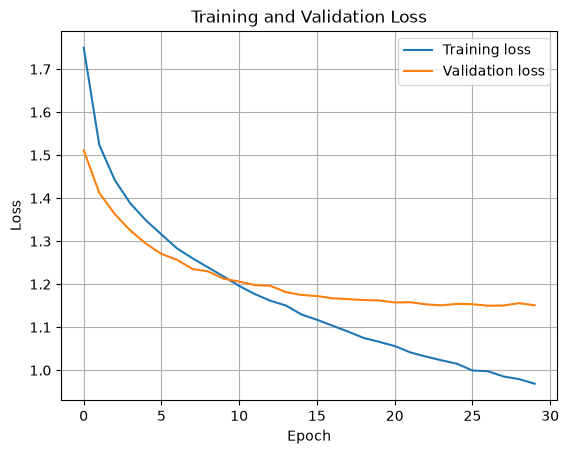

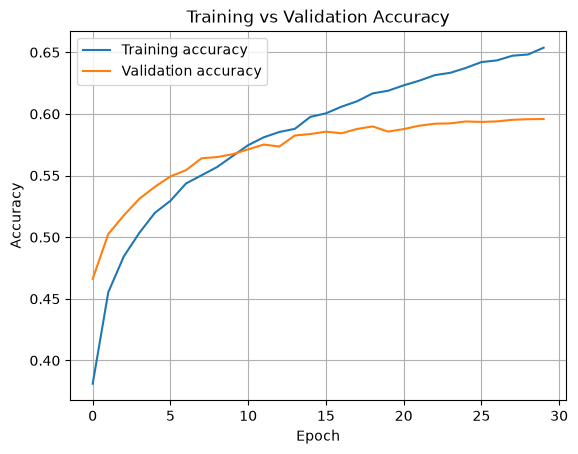

In [66]:
plt.plot(history_u.history['loss'], label='Training loss')
plt.plot(history_u.history['val_loss'], label='Validation loss')

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()
plt.grid(True)
plt.show()

plt.plot(history_u.history['accuracy'], label='Training accuracy')
plt.plot(history_u.history['val_accuracy'], label='Validation accuracy')

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training vs Validation Accuracy')
plt.legend()
plt.grid(True)
plt.show()

# 5. Evaluation of an earlier model

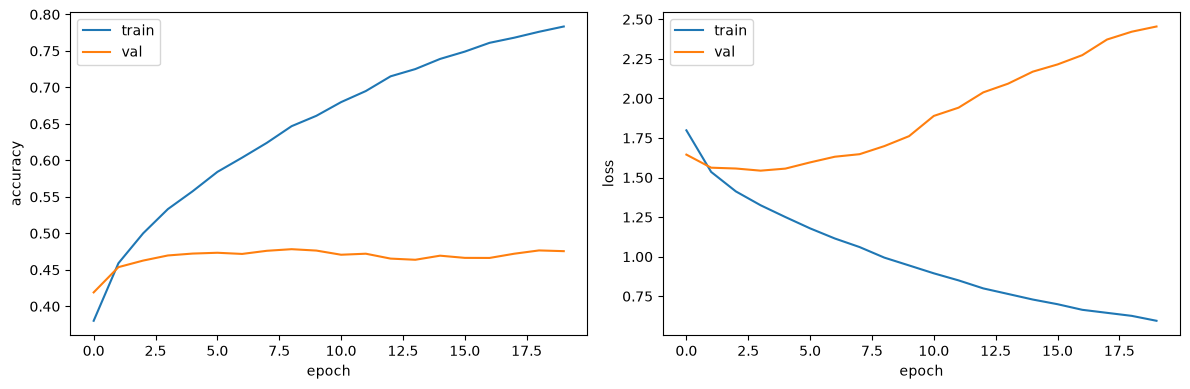

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(full_history.history["accuracy"], label="train")
axes[0].plot(full_history.history["val_accuracy"], label="val")
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("accuracy")
axes[0].legend()

axes[1].plot(full_history.history["loss"], label="train")
axes[1].plot(full_history.history["val_loss"], label="val")
axes[1].set_xlabel("epoch")
axes[1].set_ylabel("loss")
axes[1].legend()

plt.tight_layout()
plt.show()

yllä olevista kuvaajista voimme päätellä `val_loss` noususta että malli ylioppii (overfit). Lisätään aikaisemppiin mallinkoulutuksiin callback joka pysäyttää ja palauttaa parametrit jolloin `val_loss` alkoi nousta.

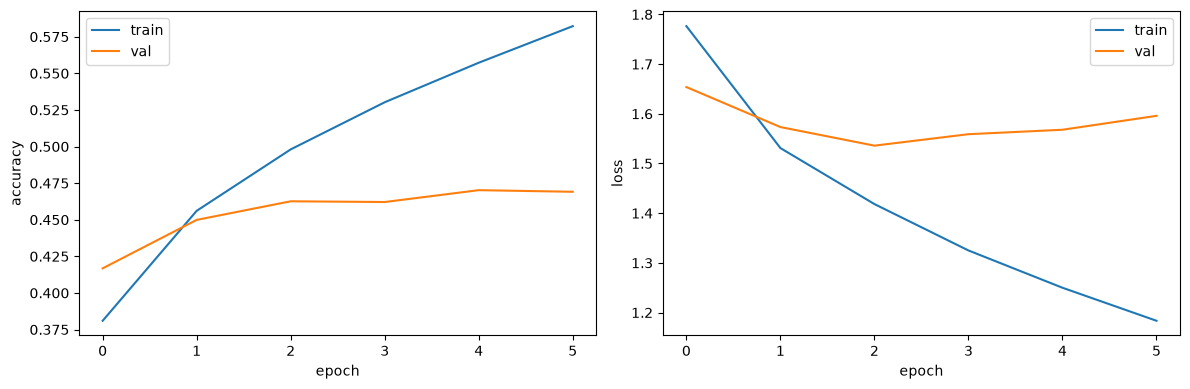

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history["accuracy"], label="train")
axes[0].plot(history.history["val_accuracy"], label="val")
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("accuracy")
axes[0].legend()

axes[1].plot(history.history["loss"], label="train")
axes[1].plot(history.history["val_loss"], label="val")
axes[1].set_xlabel("epoch")
axes[1].set_ylabel("loss")
axes[1].legend()

plt.tight_layout()
plt.show()

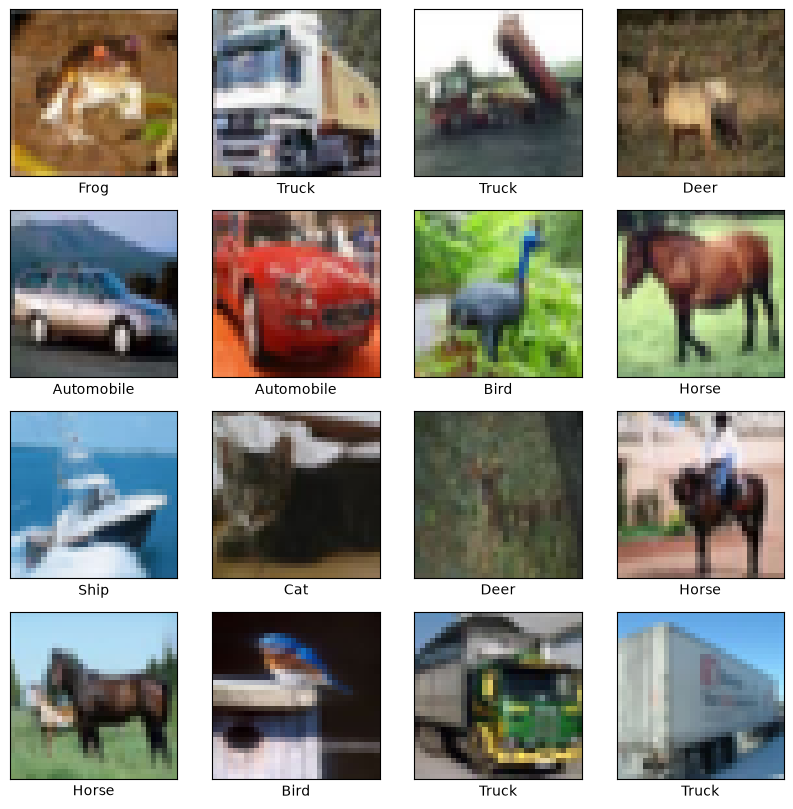

In [17]:
(x_train2, y_train2), (x_test2, y_test2) = keras.datasets.cifar10.load_data()

x_train2 = x_train2.astype("float32") / 255
x_test2 = x_test2.astype("float32") / 255

class_names = ['Airplane','Automobile','Bird','Cat','Deer','Dog','Frog','Horse','Ship','Truck']

plt.figure(figsize=(10,10))
for i in range(16):
    plt.subplot(4,4,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(x_train2[i])
    plt.xlabel(class_names[y_train2[i][0]])
plt.show()

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 885us/step
(10000, 10) 0.99999994


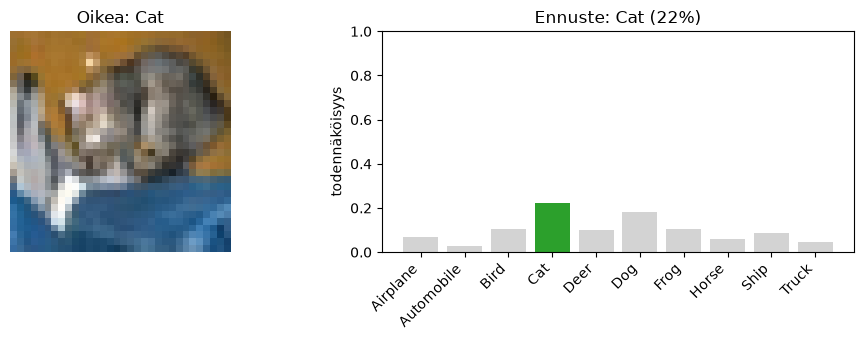

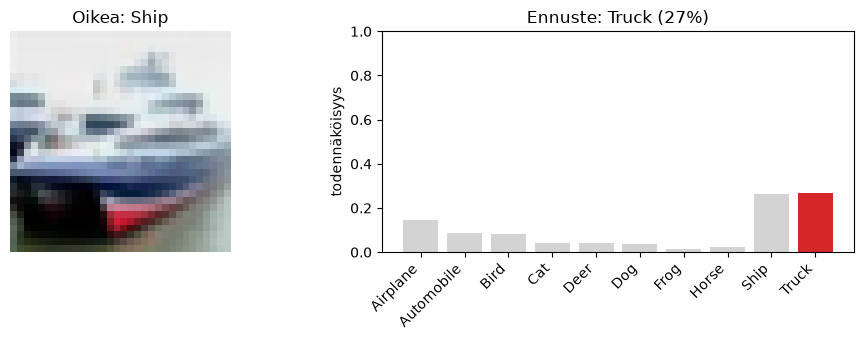

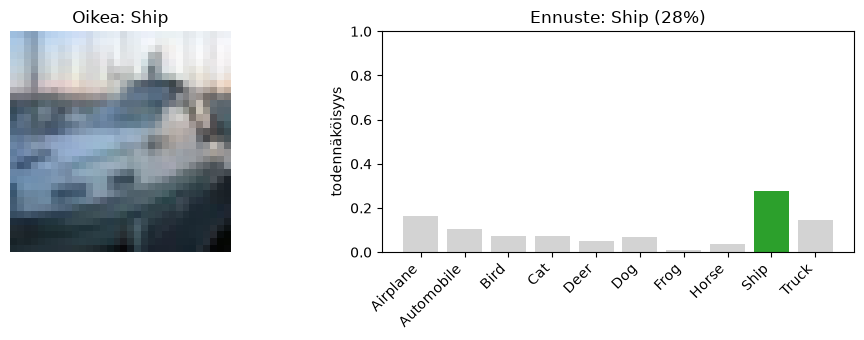

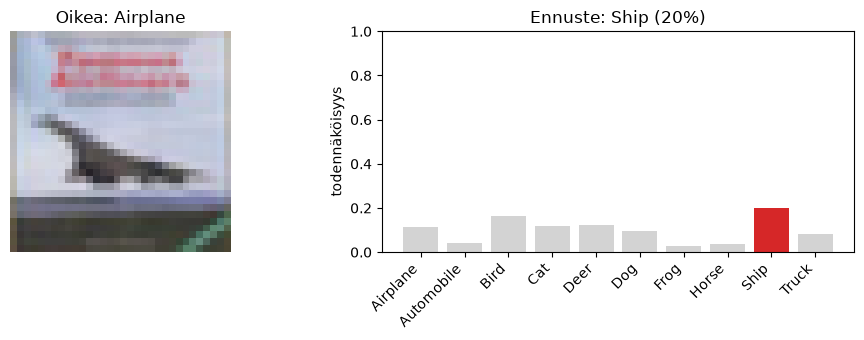

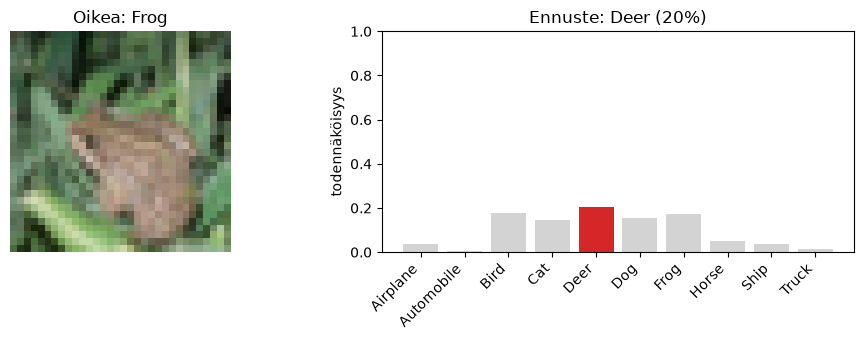

In [18]:
x_test_flat = x_test2.reshape(10000, 3072)
probs = model.predict(x_test_flat)
print(probs.shape, probs[0].sum())

(_, _), (x_test_img, y_test_int) = keras.datasets.cifar10.load_data()
x_test_img = x_test_img.astype("float32") / 255
y_test_int = y_test_int.flatten()

def plot_prediction(i, probs, images_img, true_labels):
    pred = np.argmax(probs[i])
    true = true_labels[i]

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5))

    ax1.imshow(images_img[i])
    ax1.axis("off")
    ax1.set_title(f"Oikea: {class_names[true]}")

    colors = ["lightgray"] * 10
    colors[pred] = "tab:red" if pred != true else "tab:green"
    ax2.bar(range(10), probs[i], color=colors)
    ax2.set_xticks(range(10))
    ax2.set_xticklabels(class_names, rotation=45, ha="right")
    ax2.set_ylim(0, 1)
    ax2.set_ylabel("todennäköisyys")
    ax2.set_title(f"Ennuste: {class_names[pred]} ({probs[i][pred]:.0%})")

    plt.tight_layout()
    plt.show()

for i in range(5):
    plot_prediction(i, probs, x_test_img, y_test_int)

# Kuinka usein malli ennustaa kunkin luokan oikein:

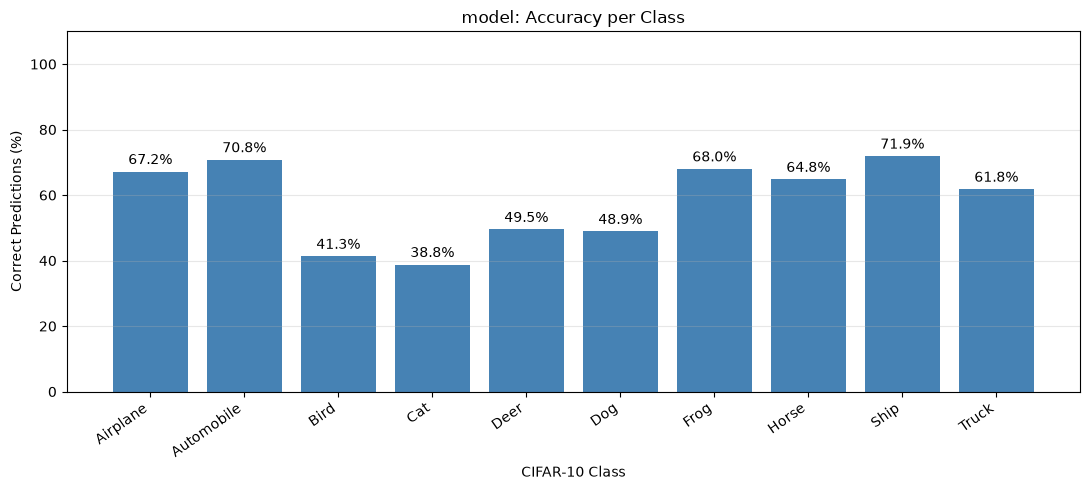

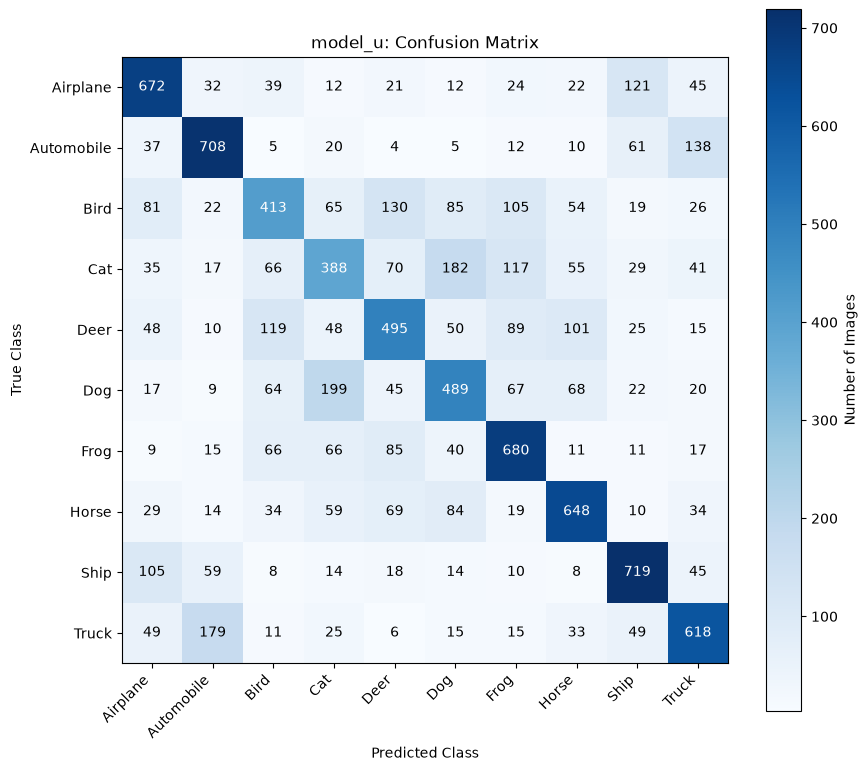

Overall test accuracy: 58.30%


In [63]:
class_names = [
    'Airplane', 'Automobile', 'Bird', 'Cat', 'Deer',
    'Dog', 'Frog', 'Horse', 'Ship', 'Truck'
]

#tekoäly antoi tämän koodin
predictions = model_u.predict(X_test, verbose=0)

y_pred = np.argmax(predictions, axis=1)
y_true = np.argmax(y_test, axis=1)

correct = np.zeros(10, dtype=int)
total = np.zeros(10, dtype=int)

for i in range(10):
    mask = (y_true == i)
    total[i] = np.sum(mask)
    correct[i] = np.sum(y_pred[mask] == i)

accuracy = np.divide(
    correct, total,
    out=np.zeros(10, dtype=float),
    where=total != 0
) * 100

plt.figure(figsize=(11, 5))
bars = plt.bar(class_names, accuracy, color='steelblue')
plt.bar_label(bars, fmt='%.1f%%', padding=3)

plt.xlabel('CIFAR-10 Class')
plt.ylabel('Correct Predictions (%)')
plt.title('model: Accuracy per Class')
plt.ylim(0, 110)
plt.xticks(rotation=35, ha='right')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

cm = np.zeros((10, 10), dtype=int)

for true, pred in zip(y_true, y_pred):
    cm[true, pred] += 1

fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(cm, cmap='Blues')

ax.set_xticks(np.arange(10))
ax.set_yticks(np.arange(10))
ax.set_xticklabels(class_names, rotation=45, ha='right')
ax.set_yticklabels(class_names)

ax.set_xlabel('Predicted Class')
ax.set_ylabel('True Class')
ax.set_title('model_u: Confusion Matrix')
fig.colorbar(im, ax=ax, label='Number of Images')

for i in range(10):
    for j in range(10):
        ax.text(
            j, i, str(cm[i, j]),
            ha='center', va='center',
            color='white' if cm[i, j] > cm.max() / 2 else 'black'
        )

plt.tight_layout()
plt.show()

print(f'Overall test accuracy: {np.mean(y_pred == y_true) * 100:.2f}%')

## Tekoälyn käyttö
tekoälyä on käytetty koodien kirjoittamisen ja eri funktioden toimninnan ymmärtämisen apuna.